# Laminated plate and ABD matrix

This example creates a laminate with `laminated_plate` and checks the
matrices it computes against the theory of laminated plates: the `ABD` matrix
of the classical laminated plate theory (CLPT) and of the first-order shear
deformation theory (FSDT), the corrected transverse shear stiffness `Ats`,
the equivalent membrane properties, the mass per unit area, the matrices of
the third-order shear deformation theory (TSDT) and the stiffnesses obtained
from lamination parameters. Each result is printed next to its reference
value, computed here independently of `composites` or by an independent
implementation, with the relative difference. SI units are used throughout.

The stacking sequence runs from the bottom to the top ply, see
[Conventions](../conventions.rst). The stiffnesses are the thickness
integrals of the ply stiffnesses $C^{(k)}$ in the laminate axes, see
[Laminate stiffness and plate theories](../constitutive_matrices.rst):

$$
(A, B, D) = \sum_k \int_{z_k}^{z_{k+1}} C^{(k)} (1, z, z^2) \, dz, \qquad
\begin{Bmatrix} N \\ M \end{Bmatrix} =
\begin{bmatrix} A & B \\ B & D \end{bmatrix}
\begin{Bmatrix} \varepsilon^{(0)} \\ \varepsilon^{(1)} \end{Bmatrix}
$$

`print_table` prints a result, its reference and the relative difference;
for a reference equal to zero the difference is divided by a scale of the
same matrix, given in the row.

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, '../tests') # independent implementation of Rohwer (1988)

import numpy as np
import matplotlib.pyplot as plt

from composites import laminated_plate
from composites.core import (laminate_from_LaminationParameters,
                             make_balanced_LP, make_orthotropic_LP,
                             make_symmetric_LP)
from test_transverse_shear import RohwerReference, stack_from_laminate

np.set_printoptions(precision=4)

def print_table(rows):
    """Print each result, its reference value and their relative difference

    ``rows`` holds ``(name, value, reference)`` or ``(name, value, reference,
    scale)``; the difference is divided by ``scale``, by default the absolute
    value of the reference, e.g. the largest term of the matrix when the
    reference is zero.
    """
    print('%-36s %14s %14s %10s' % ('quantity', 'composites', 'reference',
                                    'rel. diff.'))
    for row in rows:
        name, value, ref = row[:3]
        scale = row[3] if len(row) > 3 else abs(ref)
        print('%-36s % 14.6e % 14.6e %10.1e' % (name, value, ref,
                                               abs(value - ref)/scale))

## A quasi-isotropic laminate

The laminate $[0/45/-45/90]_s$ of a CFRP ply, eight plies of 0.125 mm, with
the density of the plies. `ABD` relates $\{N_{xx}, N_{yy}, N_{xy}, M_{xx},
M_{yy}, M_{xy}\}$ to the generalized strains $\{\varepsilon^{(0)}_{xx},
\varepsilon^{(0)}_{yy}, \gamma^{(0)}_{xy}, \varepsilon^{(1)}_{xx},
\varepsilon^{(1)}_{yy}, \gamma^{(1)}_{xy}\}$; its blocks are `lam.A`, `lam.B`
and `lam.D`.

In [2]:
# E11, E22, nu12, G12, G13, G23 of the ply
laminaprop = (142e9, 8.7e9, 0.28, 5.1e9, 5.1e9, 3.2e9)
rho = 1600. # kg/m^3
stack = [0, 45, -45, 90, 90, -45, 45, 0] # from the bottom to the top ply
lam = laminated_plate(stack, plyt=0.125e-3, laminaprop=laminaprop, rho=rho)
h = lam.h
print('h =', h)
print('ABD =')
print(lam.ABD)

h = 0.001
ABD =
[[ 5.9947e+07  1.8214e+07  0.0000e+00  0.0000e+00  8.5265e-14  0.0000e+00]
 [ 1.8214e+07  5.9947e+07  1.8626e-09  8.5265e-14 -4.5475e-13  0.0000e+00]
 [ 0.0000e+00  1.8626e-09  2.0866e+07  0.0000e+00  0.0000e+00  1.7053e-13]
 [ 0.0000e+00  8.5265e-14  0.0000e+00  8.3812e+00  1.2715e+00  5.2322e-01]
 [ 8.5265e-14 -4.5475e-13  0.0000e+00  1.2715e+00  2.1027e+00  5.2322e-01]
 [ 0.0000e+00  0.0000e+00  1.7053e-13  5.2322e-01  5.2322e-01  1.4925e+00]]


## Membrane stiffness: quasi-isotropic

The ply stiffnesses in the laminate axes are linear in $\cos 2\theta$,
$\sin 2\theta$, $\cos 4\theta$, $\sin 4\theta$, with the material invariants
$u_1, \dots, u_5$ as coefficients, see
[Ply constitutive relations and invariants](../lamina.rst):

$$
u_1 = \frac{3 Q_{11} + 3 Q_{22} + 2 Q_{12} + 4 Q_{66}}{8}, \quad
u_4 = \frac{Q_{11} + Q_{22} + 6 Q_{12} - 4 Q_{66}}{8}, \quad
u_5 = \frac{u_1 - u_4}{2},
$$

with the plane-stress stiffnesses $Q_{11} = E_1/(1 - \nu_{12} \nu_{21})$,
$Q_{22} = E_2/(1 - \nu_{12} \nu_{21})$, $Q_{12} = \nu_{12} Q_{22}$,
$Q_{66} = G_{12}$ and $\nu_{21} = \nu_{12} E_2/E_1$. For the angles 0, 45, -45
and 90 degrees, each with the same thickness, the averages of the four
trigonometric terms, the lamination parameters $\xi_{A1}, \dots, \xi_{A4}$,
are zero, and the stiffnesses of
[Lamination parameters](../lamination_parameters.rst) reduce to

$$
A_{11} = A_{22} = h u_1, \quad A_{12} = h u_4, \quad A_{66} = h u_5, \quad
A_{16} = A_{26} = 0,
$$

the form of the membrane stiffness of an isotropic plate. The laminate is
symmetric about the mid-surface and has no offset, so the integrand
$C^{(k)} z$ is odd about $z = 0$ and $B = 0$. Below, the invariants are
computed from the ply constants, independently of `composites`.

In [3]:
E1, E2, nu12, G12 = laminaprop[:4]
nu21 = nu12*E2/E1
Q11 = E1/(1 - nu12*nu21)
Q22 = E2/(1 - nu12*nu21)
Q12 = nu12*Q22
Q66 = G12
u1 = (3*Q11 + 3*Q22 + 2*Q12 + 4*Q66)/8
u4 = (Q11 + Q22 + 6*Q12 - 4*Q66)/8
u5 = (u1 - u4)/2
print_table([
    ('A11 = h u1', lam.A11, h*u1),
    ('A22 = h u1', lam.A22, h*u1),
    ('A12 = h u4', lam.A12, h*u4),
    ('A66 = h u5', lam.A66, h*u5),
    ('A16 = 0 (scale A11)', lam.A16, 0., lam.A11),
    ('A26 = 0 (scale A11)', lam.A26, 0., lam.A11),
    ('max |Bij| = 0 (scale A11 h)', np.abs(lam.B).max(), 0., lam.A11*h),
])

quantity                                 composites      reference rel. diff.
A11 = h u1                             5.994720e+07   5.994720e+07    2.5e-16
A22 = h u1                             5.994720e+07   5.994720e+07    2.5e-16
A12 = h u4                             1.821424e+07   1.821424e+07    0.0e+00
A66 = h u5                             2.086648e+07   2.086648e+07    3.6e-16
A16 = 0 (scale A11)                    0.000000e+00   0.000000e+00    0.0e+00
A26 = 0 (scale A11)                    1.862645e-09   0.000000e+00    3.1e-17
max |Bij| = 0 (scale A11 h)            4.547474e-13   0.000000e+00    7.6e-18


## Bending stiffness: not quasi-isotropic

In $D$ the trigonometric terms are weighted with $z^2$. The +45 degree plies
are farther from the mid-surface than the -45 degree plies, so the
bending-twisting terms $D_{16}$ and $D_{26}$ are not zero and the bending
stiffness depends on the direction. Rotating the stacking sequence by an
angle $\psi$, `stack - psi`, gives the stiffnesses in axes rotated by $\psi$:
$A_{11}$ is the same in every direction, $D_{11}$ is not.

D16/D11 = 0.0624, D26/D11 = 0.0624
A11 over the directions: max/min - 1 = 1.3e-15
D11 over the directions: max/min = 4.560


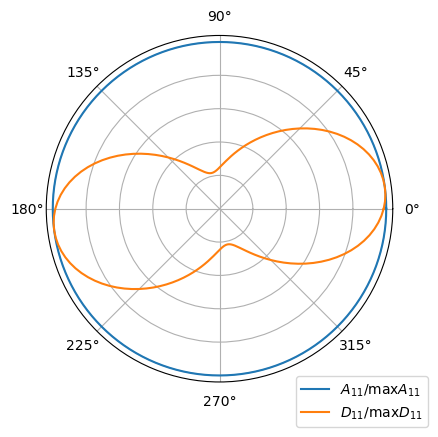

In [4]:
print('D16/D11 = %.4f, D26/D11 = %.4f' % (lam.D16/lam.D11, lam.D26/lam.D11))
psis = np.linspace(0, 360, 145)
A11s, D11s = [], []
for psi in psis:
    rot = laminated_plate(np.array(stack) - psi, plyt=0.125e-3,
                          laminaprop=laminaprop)
    A11s.append(rot.A11)
    D11s.append(rot.D11)
A11s, D11s = np.array(A11s), np.array(D11s)
print('A11 over the directions: max/min - 1 = %.1e' % (A11s.max()/A11s.min() - 1))
print('D11 over the directions: max/min = %.3f' % (D11s.max()/D11s.min()))

fig = plt.figure(figsize=(4.5, 4.5))
ax = fig.add_subplot(projection='polar')
ax.plot(np.deg2rad(psis), A11s/A11s.max(), label='$A_{11}/\\max A_{11}$')
ax.plot(np.deg2rad(psis), D11s/D11s.max(), label='$D_{11}/\\max D_{11}$')
ax.set_yticklabels([])
ax.legend(loc='lower left', bbox_to_anchor=(0.7, -0.15))
plt.show()

## Equivalent properties, transverse shear and mass

The equivalent membrane properties follow from the compliance
$a = [[A, B], [B, D]]^{-1}$: $E_1 = 1/(h a_{11})$, $E_2 = 1/(h a_{22})$,
$G_{12} = 1/(h a_{66})$ and $\nu_{12} = -a_{12}/a_{11}$. Since $B = 0$, the
membrane block of $a$ is $A^{-1}$, and the isotropic form of $A$ gives
$E_1 = E_2$ and $G_{12} = E_1/(2(1 + \nu_{12}))$.

`Ats` is the transverse shear stiffness of the FSDT with the shear correction
applied, by default with the equilibrium approach of Rohwer [1], see
[Shear correction](../shear_correction.rst). In two cylindrical bending
states, $M_{xx,x} = Q_x$, $M_{xy,x} = Q_y$ and $M_{yy,y} = Q_y$,
$M_{xy,y} = Q_x$, the equilibrium equations $\tau_{xz,z} = -\sigma_{xx,x}$ and
$\tau_{yz,z} = -\sigma_{yy,y}$ give a distribution
$\{\tau_{yz}, \tau_{xz}\} = f^{(k)}(z) \, Q$, quadratic within each ply, and
the stiffness follows from the complementary energy, Rohwer's Eq. (43):

$$
A_{ts} = \left[ \sum_k \int_{z_k}^{z_{k+1}} f^{(k)T}
\left(C_s^{(k)}\right)^{-1} f^{(k)} \, dz \right]^{-1}
$$

The reference is `RohwerReference`, an independent NumPy implementation of
these equations kept with the tests of `composites`, which integrates the
energy, of degree 4 in $z$, with the 3-point Gauss-Legendre rule per ply,
exact for this degree. The two implementations solve the same equations, so
they agree to round-off. The informative factors are the ratios to the
constant-strain stiffness $\bar{A}_{ts}$: `scf_k13 = A55/Abar55` and
`scf_k23 = A44/Abar44`. The mass per unit area is
$I_0 = \sum_k \int \rho^{(k)} dz = \rho h$, see
[Mass integrals](../mass_integrals.rst).

In [5]:
Ats_ref = RohwerReference(stack_from_laminate(lam)).Ats
print('Ats =')
print(lam.Ats)
print('scf_k13 = %.4f, scf_k23 = %.4f' % (lam.scf_k13, lam.scf_k23))
print()
print_table([
    ('e2 = e1', lam.e2, lam.e1),
    ('g12 = e1/(2 (1 + nu12))', lam.g12, lam.e1/(2*(1 + lam.nu12))),
    ('A44, Rohwer (1988)', lam.A44, Ats_ref[0, 0]),
    ('A45, Rohwer (1988), scale A55', lam.A45, Ats_ref[0, 1], Ats_ref[1, 1]),
    ('A55, Rohwer (1988)', lam.A55, Ats_ref[1, 1]),
    ('intrho = rho h', lam.intrho, rho*h),
])

Ats =
[[2948931.4831   43511.7955]
 [  43511.7955 3247625.5097]]
scf_k13 = 0.7826, scf_k23 = 0.7106

quantity                                 composites      reference rel. diff.
e2 = e1                                5.441302e+10   5.441302e+10    0.0e+00
g12 = e1/(2 (1 + nu12))                2.086648e+10   2.086648e+10    0.0e+00
A44, Rohwer (1988)                     2.948931e+06   2.948931e+06    4.7e-16
A45, Rohwer (1988), scale A55          4.351180e+04   4.351180e+04    2.4e-16
A55, Rohwer (1988)                     3.247626e+06   3.247626e+06    7.2e-16
intrho = rho h                         1.600000e+00   1.600000e+00    1.4e-16


## An unsymmetric laminate: TSDT and transverse shear

The unsymmetric laminate $[0/45/90]$, plies of 0.125 mm of a material with
$E_1 = 71$ GPa, $E_2 = 7$ GPa, $\nu_{12} = 0.28$ and
$G_{12} = G_{13} = G_{23} = G = 7$ GPa, has $B \neq 0$ and, for the TSDT, the
odd integral $E \neq 0$. The uncorrected transverse shear matrices of the
TSDT are

$$
(\bar{A}_{ts}, D_{ts}, F_{ts}) = \sum_k \int_{z_k}^{z_{k+1}} C_s^{(k)}
(1, z^2, z^4) \, dz.
$$

With $G_{13} = G_{23} = G$ the transverse shear stiffness of every ply is
$C_s^{(k)} = G I$ for any angle, hence the closed forms
$\bar{A}_{ts} = G h I$, $D_{ts} = G h^3/12 \, I$ and
$F_{ts} = G h^5/80 \, I$. Since $G_{13} = G_{23}$, $\bar{A}_{45} = 0$; the
coupling $A_{45} \neq 0$ of the equilibrium approach comes from the in-plane
couplings of the 45 degree ply.

In [6]:
lamprop = (71e9, 7e9, 0.28, 7e9, 7e9, 7e9)
stack2 = [0, 45, 90]
plyt = 0.125e-3
lam2 = laminated_plate(stack2, plyt, lamprop)
G, h2 = 7e9, lam2.h
Ats_ref2 = RohwerReference(stack_from_laminate(lam2)).Ats
print('B =')
print(lam2.B)
print('E =')
print(lam2.E)
print()
print_table([
    ('Abar44 = G h', lam2.Abar44, G*h2),
    ('Abar55 = G h', lam2.Abar55, G*h2),
    ('Abar45 = 0 (scale G h)', lam2.Abar45, 0., G*h2),
    ('Dts[0, 0] = G h^3/12', lam2.Dts[0, 0], G*h2**3/12),
    ('Dts[1, 1] = G h^3/12', lam2.Dts[1, 1], G*h2**3/12),
    ('Fts[0, 0] = G h^5/80', lam2.Fts[0, 0], G*h2**5/80),
    ('Fts[1, 1] = G h^5/80', lam2.Fts[1, 1], G*h2**5/80),
    ('A44, Rohwer (1988)', lam2.A44, Ats_ref2[0, 0]),
    ('A45, Rohwer (1988)', lam2.A45, Ats_ref2[0, 1]),
    ('A55, Rohwer (1988)', lam2.A55, Ats_ref2[1, 1]),
])

B =
[[-1.0078e+03  0.0000e+00  8.5350e-15]
 [ 0.0000e+00  1.0078e+03  5.3174e-14]
 [ 8.5350e-15  5.3174e-14  0.0000e+00]]
E =
[[-1.9683e-05  0.0000e+00  1.6670e-22]
 [ 0.0000e+00  1.9683e-05  1.0386e-21]
 [ 1.6670e-22  1.0386e-21  0.0000e+00]]

quantity                                 composites      reference rel. diff.
Abar44 = G h                           2.625000e+06   2.625000e+06    0.0e+00
Abar55 = G h                           2.625000e+06   2.625000e+06    0.0e+00
Abar45 = 0 (scale G h)                 0.000000e+00   0.000000e+00    0.0e+00
Dts[0, 0] = G h^3/12                   3.076172e-02   3.076172e-02    0.0e+00
Dts[1, 1] = G h^3/12                   3.076172e-02   3.076172e-02    0.0e+00
Fts[0, 0] = G h^5/80                   6.488800e-10   6.488800e-10    0.0e+00
Fts[1, 1] = G h^5/80                   6.488800e-10   6.488800e-10    0.0e+00
A44, Rohwer (1988)                     2.014905e+06   2.014905e+06    9.2e-16
A45, Rohwer (1988)                    -2.721029e+04  

## Lamination parameters and special laminates

For a laminate of a single material the stiffnesses $A$, $B$, $D$ are linear
in the lamination parameters, with the invariants as coefficients
([Lamination parameters](../lamination_parameters.rst); Jones [2], Eq.
(4.24)). `laminate_from_LaminationParameters` with the parameters of
`calc_lamination_parameters` therefore gives back the $A$, $B$ and $D$ of
`laminated_plate`. A laminate created from lamination parameters has no
plies, hence no shear correction: its `Ats` is the constant-strain
$\bar{A}_{ts}$ of the original laminate.

`make_balanced`, `make_orthotropic` and `make_symmetric` set to zero the
integrals that vanish in a balanced, orthotropic or symmetric laminate, and
`make_balanced_LP`, `make_orthotropic_LP` and `make_symmetric_LP` set to zero
the corresponding lamination parameters, so that both paths give the same
matrices, see [Laminate stiffness and plate theories](../constitutive_matrices.rst).
Below, the balanced laminate is made orthotropic in a second step, and the
symmetric one is made from the original laminate. The table gives the largest
difference of each matrix divided by its largest term.

In [7]:
def max_rel(X, Xref):
    return np.abs(np.asarray(X) - np.asarray(Xref)).max()/np.abs(Xref).max()

matlamina = lam2.plies[0].matlamina
cases = []
lam_c = laminated_plate(stack2, plyt, lamprop)
lp = lam_c.calc_lamination_parameters()
for name, make, make_LP in (('as built', None, None),
                            ('balanced', 'make_balanced', make_balanced_LP),
                            ('balanced, orthotropic', 'make_orthotropic',
                             make_orthotropic_LP)):
    if make is not None:
        getattr(lam_c, make)()
        make_LP(lp)
    lam_lp = laminate_from_LaminationParameters(lam_c.h, matlamina, lp)
    cases.append((name, max_rel(lam_lp.ABD, lam_c.ABD),
                  max_rel(lam_lp.Ats, lam_c.Abar_ts)))
lam_s = laminated_plate(stack2, plyt, lamprop)
lp_s = lam_s.calc_lamination_parameters()
lam_s.make_symmetric()
make_symmetric_LP(lp_s)
lam_lp = laminate_from_LaminationParameters(lam_s.h, matlamina, lp_s)
cases.append(('symmetric', max_rel(lam_lp.ABD, lam_s.ABD),
              max_rel(lam_lp.Ats, lam_s.Abar_ts)))

print('%-24s %22s %22s' % ('laminate', 'ABD, rel. diff.', 'Ats vs Abar_ts'))
for name, diff_ABD, diff_Ats in cases:
    print('%-24s %22.1e %22.1e' % (name, diff_ABD, diff_Ats))

laminate                        ABD, rel. diff.         Ats vs Abar_ts
as built                                1.4e-16                0.0e+00
balanced                                1.4e-16                0.0e+00
balanced, orthotropic                   1.4e-16                0.0e+00
symmetric                               1.4e-16                0.0e+00


`make_smeared` is the limit of many repetitions of the stacking sequence:
$B = 0$ and $D = h^2 A/12$, the stiffnesses of a homogeneous plate.

In [8]:
lam4 = laminated_plate(stack2, plyt, lamprop)
lam4.make_smeared()
print('D =')
print(lam4.D)
print('D vs h^2 A/12, rel. diff. %.1e' % max_rel(lam4.D, lam4.h**2*lam4.A/12))
print('max |Bij| = %.1e' % np.abs(lam4.B).max())

D =
[[0.1556 0.0258 0.0236]
 [0.0258 0.1556 0.0236]
 [0.0236 0.0236 0.0478]]
D vs h^2 A/12, rel. diff. 0.0e+00
max |Bij| = 0.0e+00


## References

1. Rohwer, K., Improved Transverse Shear Stiffnesses for Layered Finite Elements, DFVLR-FB 88-32, 1988.
2. Jones, R. M., Mechanics of Composite Materials, Second Edition, Taylor & Francis, Philadelphia, 1999.